<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MOBILE PRICE DATASET
   battery_power   ram  internal_memory  camera  battery  screen_size  \
0           1000   512                8       2     2000          4.0   
1           1200   768                8       3     2200          4.2   
2           1500  1024               16       5     2500          4.5   
3           1800  2048               32       8     3000          5.0   
4           2000  4096               64      16     4000          6.0   

   price_range  
0            0  
1            0  
2            1  
3            2  
4            3  

Dataset Shape: (30, 7)

Missing Values:
battery_power      0
ram                0
internal_memory    0
camera             0
battery            0
screen_size        0
price_range        0
dtype: int64

Model Training Completed Successfully!

ACTUAL VS PREDICTED PRICE RANGE
   Actual Price Range  Predicted Price Range
0                   0                      0
1                   3                      3
2                   1        

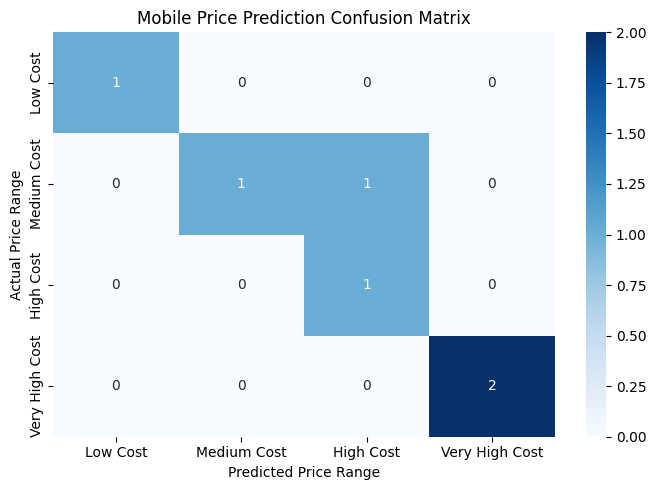


FEATURE IMPORTANCE
           Feature  Importance
0    battery_power    0.208800
4          battery    0.202824
5      screen_size    0.168239
1              ram    0.147995
2  internal_memory    0.141102
3           camera    0.131040


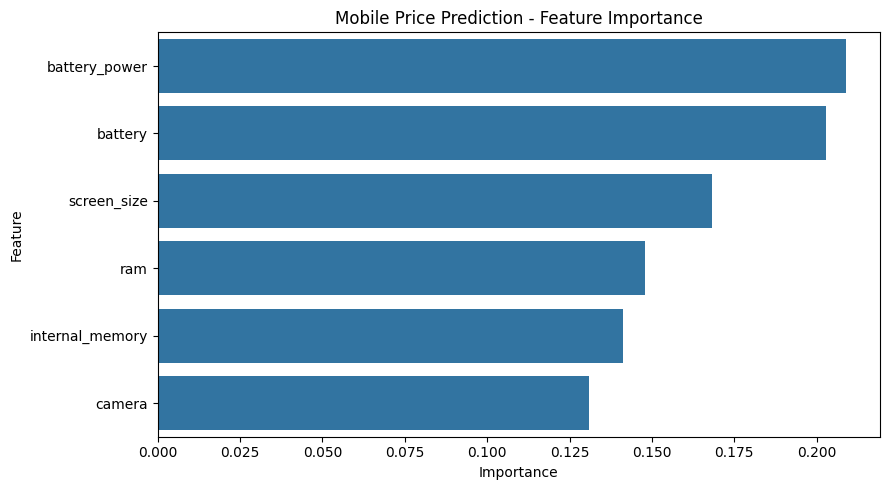


NEW MOBILE DETAILS
   battery_power   ram  internal_memory  camera  battery  screen_size
0           2000  4096               64      16     4000          6.0

PREDICTED MOBILE PRICE RANGE: Very High Cost

PREDICTION PROBABILITIES
Low Cost : 0.0 %
Medium Cost : 0.0 %
High Cost : 1.0 %
Very High Cost : 99.0 %

Dataset and prediction results saved successfully!


In [1]:

# MOBILE PRICE PREDICTION USING RANDOM FOREST

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Step 2: Create Sample Mobile Dataset
data = {
    'battery_power': [
        1000, 1200, 1500, 1800, 2000,
        1100, 1300, 1600, 1900, 2100,
        900, 1400, 1700, 1950, 2200,
        1050, 1250, 1550, 1850, 2150,
        1150, 1450, 1750, 2050, 2250,
        950, 1350, 1650, 1950, 2300
    ],

    'ram': [
        512, 768, 1024, 2048, 4096,
        512, 768, 1536, 2048, 4096,
        256, 1024, 1536, 3072, 4096,
        512, 1024, 1536, 2048, 4096,
        768, 1024, 2048, 3072, 4096,
        256, 1024, 1536, 3072, 4096
    ],

    'internal_memory': [
        8, 8, 16, 32, 64,
        8, 16, 16, 32, 64,
        4, 16, 32, 32, 64,
        8, 16, 32, 64, 64,
        16, 16, 32, 64, 128,
        4, 16, 32, 64, 128
    ],

    'camera': [
        2, 3, 5, 8, 16,
        2, 5, 8, 12, 16,
        2, 5, 8, 12, 20,
        3, 5, 8, 12, 16,
        5, 8, 12, 16, 20,
        2, 5, 8, 16, 20
    ],

    'battery': [
        2000, 2200, 2500, 3000, 4000,
        1800, 2300, 2600, 3200, 4200,
        1500, 2400, 2700, 3500, 4500,
        1900, 2500, 2800, 3300, 4300,
        2200, 2600, 3000, 3800, 5000,
        1600, 2400, 2900, 3700, 5000
    ],

    'screen_size': [
        4.0, 4.2, 4.5, 5.0, 6.0,
        4.0, 4.5, 5.0, 5.5, 6.2,
        3.8, 4.5, 5.0, 5.8, 6.5,
        4.2, 4.6, 5.1, 5.8, 6.2,
        4.5, 5.0, 5.5, 6.0, 6.7,
        3.8, 4.5, 5.2, 6.0, 6.8
    ],

    'price_range': [
        0, 0, 1, 2, 3,
        0, 1, 1, 2, 3,
        0, 1, 1, 2, 3,
        0, 1, 2, 2, 3,
        1, 1, 2, 3, 3,
        0, 1, 2, 3, 3
    ]
}

df = pd.DataFrame(data)

# Step 3: Display Dataset
print("MOBILE PRICE DATASET")
print(df.head())

print("\nDataset Shape:", df.shape)

# Step 4: Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 5: Separate Input and Output
X = df.drop('price_range', axis=1)
y = df['price_range']

# Step 6: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 7: Create Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 8: Train Model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 9: Predict Test Data
y_pred = model.predict(X_test)

print("\nACTUAL VS PREDICTED PRICE RANGE")

results = pd.DataFrame({
    'Actual Price Range': y_test.values,
    'Predicted Price Range': y_pred
})

print(results)

# Step 10: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL ACCURACY")
print("Accuracy: {:.2f}%".format(accuracy * 100))

# Step 11: Classification Report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Step 12: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ],
    yticklabels=[
        'Low Cost',
        'Medium Cost',
        'High Cost',
        'Very High Cost'
    ]
)

plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")
plt.title("Mobile Price Prediction Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# Step 13: Feature Importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFEATURE IMPORTANCE")
print(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Mobile Price Prediction - Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

# Step 14: Predict New Mobile Price Range

new_mobile = pd.DataFrame({
    'battery_power': [2000],
    'ram': [4096],
    'internal_memory': [64],
    'camera': [16],
    'battery': [4000],
    'screen_size': [6.0]
})

prediction = model.predict(new_mobile)

price_categories = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}

print("\nNEW MOBILE DETAILS")
print(new_mobile)

print("\nPREDICTED MOBILE PRICE RANGE:",
      price_categories[prediction[0]])

# Step 15: Prediction Probabilities
probabilities = model.predict_proba(new_mobile)

print("\nPREDICTION PROBABILITIES")

for category, probability in zip(
    model.classes_, probabilities[0]
):
    print(
        price_categories[category],
        ":",
        round(probability * 100, 2),
        "%"
    )

# Step 16: Save Results
results.to_csv("mobile_prediction_results.csv", index=False)

df.to_csv("mobile_dataset.csv", index=False)

print("\nDataset and prediction results saved successfully!")
